# 🐍 Clase 43 — Construir una neurona

**Curso:** 3ro medio  |  **Duración:** 80 min  |  **Plataforma:** Google Colab

---

## 🎯 Objetivo de la clase

Crear nuestra primera inteligencia artificial: una neurona, con asombro.

## 🔎 ¿Por qué lo veremos?

🎙️ *Lo dice el colega del profesor:*

> «Yo estoy hecha de miles de millones de piezas pequeñas llamadas neuronas. Hoy ustedes van a construir la primera, desde cero. Con ella van a poner los cimientos de lo que yo soy.»

---

**Lo que ya sabes:** todo lo dictado hasta N°42 (las entradas y las etiquetas, `fit()` y `predict()`) y Python hasta listas, `for` y funciones.

**Lo que aprenderás hoy:** calcular la salida de una neurona con una **suma ponderada**, un **sesgo** y una **activación escalón**, y ajustar sus pesos a mano mirando el **entrenamiento** y comprobando después en una **prueba**. **Todos los datos vienen escritos en este cuaderno** (sin archivos ni descargas) y se ejecuta de arriba hacia abajo.

---

## 1️⃣ Haz Ahora

Un apicultor de Isla de Maipo quiere automatizar algo: que un programa le diga cada mañana si sus abejas saldrán a buscar néctar. Pero tú no sabes nada de abejas, y él tampoco sabe programar. Ayúdalo a pensar cómo lo harías:

1. Tú no sabes nada de abejas. ¿Qué le pedirías al apicultor para empezar a descubrir cuándo salen?
2. Con esos registros, ¿qué patrón buscarías primero entre los días en que salen y los días en que se quedan?
3. Si ves que «con mucho viento casi nunca salen», ¿cómo convertirías eso en un número que un programa pueda usar?
4. ¿Cómo comprobarías que tu regla funciona antes de dársela al apicultor?

El apicultor, sabiendo que programamos, nos pide ayuda — pero antes quiere que tengamos clara la lógica.

**Mis respuestas:**

1. 
2. 
3. 
4. 

---

### 🔁 Ayer → 🔀 Hoy → ➡️ Después

- 🔁 **Ayer:** el árbol de decisión **aprendió solo** una cadena de preguntas sí/no. Nosotros solo le dimos datos.
- 🔀 **Hoy es distinto:** la neurona no hace preguntas, hace una **suma de datos × importancia** y decide al final. Y esta vez **la regla la armamos nosotros**, moviendo pesos y sesgo para ver cómo piensa.
- ➡️ **La próxima clase:** la computadora **aprenderá sola** esos mismos números, y compararemos con los nuestros.

| | Árbol (clase 42) | Neurona (hoy) |
|---|---|---|
| Cómo decide | Cadena de preguntas sí/no | Suma de datos × pesos + sesgo, y un sí/no al final |
| Quién armó la regla | La computadora (`fit`) | Nosotros, a mano |
| Qué se puede mover | Nada a mano | Perillas: pesos y sesgo |

**Árbol = preguntas · neurona = suma de importancias · la próxima clase = la computadora ajusta los números.**

---

## 2️⃣ Introducción al Contenido Nuevo

Hoy partimos al revés: **primero usamos una neurona ya armada** (una «caja lista») y moviendo sus números vemos cómo cambia. Después **abrimos la caja** y escribimos tú las piezas que tiene adentro.

### 🧰 Paso 0 · Los datos y la caja lista

El apicultor anotó **12 días** de sus colmenas. Cada día es una lista `[temperatura, viento, lluvia]` y su etiqueta dice si las abejas salieron (`1`) o se quedaron (`0`).

| Dato | Qué es | Ejemplo |
|---|---|---|
| `temperatura` | grados a las 9:00 | 24 |
| `viento` | km/h | 5 |
| `lluvia` | milímetros | 0 |
| etiqueta | `1` = las abejas salieron · `0` = se quedaron (**lo definimos nosotros**) | 1 |

Los 12 días se separan en dos grupos, y esta separación vale para **toda IA que se entrena**:

- **8 días de ENTRENAMIENTO** — «aquí ajustamos»: podemos mirarlos todas las veces que queramos.
- **4 días de PRUEBA** — «aquí vemos si es capaz de predecir» días que nunca vio. **Se miran una sola vez, al final.** Si ajustáramos los pesos mirándola, dejaría de ser una prueba.

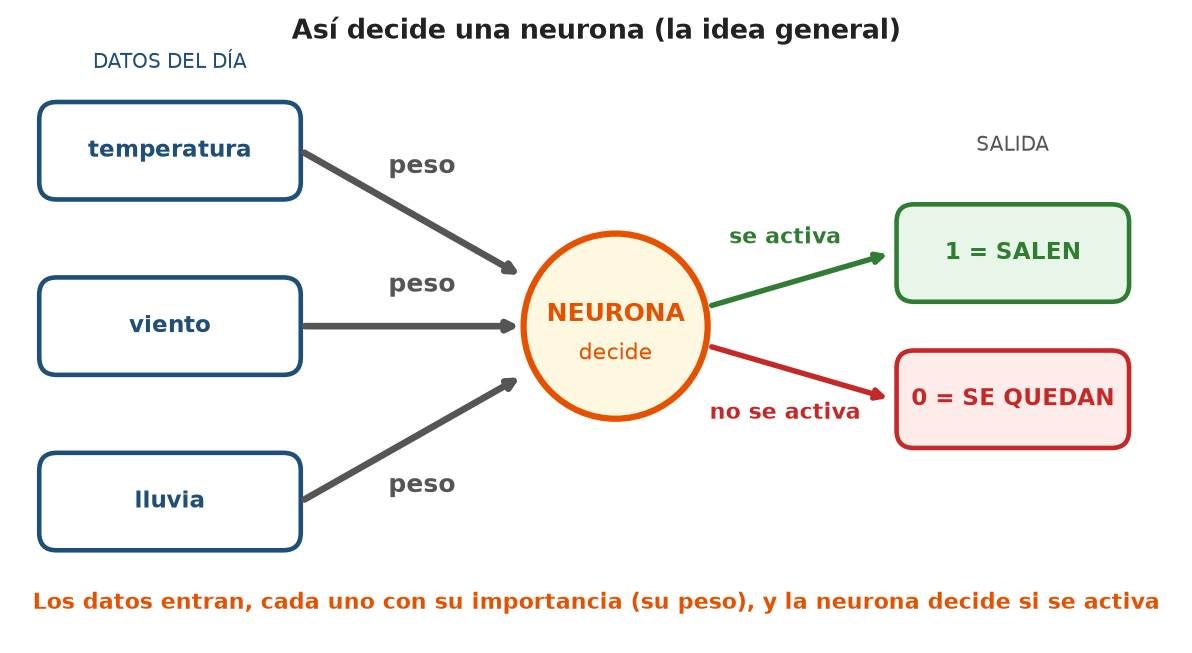

Este es el esquema general de lo que vamos a construir: los datos entran, cada línea trae un **peso** (la importancia de ese dato) y la neurona decide si se **activa** (sale 1) o no (sale 0). Los números concretos los iremos viendo paso a paso.

In [ ]:
# Datos de las colmenas (ya escritos)
dias = [[24, 5, 0], [28, 10, 0], [19, 3, 0], [30, 20, 0],
        [22, 8, 0], [26, 6, 4], [14, 4, 0], [25, 28, 0]]   # ENTRENAMIENTO: [temperatura, viento, lluvia]
etiquetas = [1, 1, 1, 0, 1, 0, 0, 0]                        # 1 = las abejas salieron, 0 = se quedaron
dias_prueba = [[27, 12, 0], [18, 6, 0], [21, 10, 0], [29, 24, 0]]   # PRUEBA: días nuevos
etiquetas_prueba = [1, 0, 1, 0]

In [ ]:
#@title 🔧 Evaluador listo — ejecuta esta celda primero (no la edites)
_PRUEBAS_VISTAS = {}


def _regla():
    print("Regla actual → pesos:", pesos, "| sesgo:", sesgo)


def _tabla(dias_, etiquetas_, nombre):
    aciertos = 0
    for i in range(len(dias_)):
        salida = neurona(dias_[i])
        error = etiquetas_[i] - salida
        if error == 0:
            aciertos = aciertos + 1
            marca = "✅"
        else:
            marca = "❌"
        print("Día", i + 1, "| datos:", dias_[i], "| salida:", salida, "| etiqueta:", etiquetas_[i], "| error:", error, marca)
    print("\n" + nombre + ":", aciertos, "de", len(dias_), "días acertados")


def evaluar_entrenamiento():
    """Prueba la neurona con los días de ENTRENAMIENTO (dias, etiquetas). Aquí sí puedes ajustar."""
    _regla()
    _tabla(dias, etiquetas, "Aciertos en ENTRENAMIENTO")


def evaluar_prueba():
    """Prueba la neurona con los días nuevos (dias_prueba, etiquetas_prueba). Se mira UNA sola vez, al final."""
    clave = str(dias_prueba)
    _PRUEBAS_VISTAS[clave] = _PRUEBAS_VISTAS.get(clave, 0) + 1
    if _PRUEBAS_VISTAS[clave] > 1:
        print("⚠️ Ya miraste la prueba antes. Si cambias los pesos mirándola, la prueba deja de ser prueba: ajusta solo con el entrenamiento.\n")
    _regla()
    _tabla(dias_prueba, etiquetas_prueba, "Aciertos en PRUEBA (días nuevos)")


print("Evaluador listo ✅")

🎛️ **Juega con la caja lista (3 minutos):** cambia los números de `pesos` y `sesgo`, ejecuta y mira cuántos días del **entrenamiento** acierta la neurona. Todavía no hace falta entender cómo funciona por dentro. ¿Puedes llegar a 8 de 8?

> Mientras tanto, también puedes jugar en la página: [https://clases-ia-mario-bertero.vercel.app/clase-43/](https://clases-ia-mario-bertero.vercel.app/clase-43/)

In [ ]:
# 🎛️ Cambia los números de pesos y sesgo, ejecuta y mira cuántos días acierta
pesos = [1, -0.5, -2]   # importancia de temperatura, viento y lluvia
sesgo = -13

# La neurona ya viene escrita (adentro de la caja):
def neurona(dia):
    z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2] + sesgo
    if z >= 0:
        return 1
    return 0

evaluar_entrenamiento()

### 💡 Ahora abrimos la caja · Suma ponderada

La neurona de partida tiene un **peso** por cada dato: `pesos = [1, -0.5, -2]`. El calor suma, el viento y la lluvia restan.

La suma ponderada se escribe así (con $x$ los datos y $w$ los pesos):

$$z = w_1 x_1 + w_2 x_2 + w_3 x_3$$

> **Idea clave:** cada dato se multiplica por su peso (su importancia) y se suman los resultados; un peso negativo frena.

✍️ **Escríbelo tú:** calcula `z` para el primer día multiplicando cada dato por su peso y sumando los tres resultados; muéstralo con una etiqueta clara.

In [ ]:
# Datos de las colmenas y neurona de partida (ya escritos)
dias = [[24, 5, 0], [28, 10, 0], [19, 3, 0], [30, 20, 0],
        [22, 8, 0], [26, 6, 4], [14, 4, 0], [25, 28, 0]]   # ENTRENAMIENTO: [temperatura, viento, lluvia]
etiquetas = [1, 1, 1, 0, 1, 0, 0, 0]                        # 1 = las abejas salieron, 0 = se quedaron

pesos = [1, -0.5, -2]   # importancia de temperatura, viento y lluvia
sesgo = -13

dia = dias[0]   # [temperatura, viento, lluvia] del primer día

### 💡 El sesgo

Además de los pesos, una neurona tiene un **sesgo**: un número que se suma al final y que empuja a la neurona a activarse más fácil o más difícil. Aquí el sesgo es `-13`: es como una «exigencia mínima» de ánimo para que las abejas salgan.

$$z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b$$

> **Idea clave:** el sesgo es el empujón inicial: un sesgo muy negativo vuelve a la neurona exigente.

✍️ **Escríbelo tú:** suma el sesgo al valor de `z` y muestra el nuevo `z`.

In [ ]:
# Datos de las colmenas y neurona de partida (ya escritos)
dias = [[24, 5, 0], [28, 10, 0], [19, 3, 0], [30, 20, 0],
        [22, 8, 0], [26, 6, 4], [14, 4, 0], [25, 28, 0]]   # ENTRENAMIENTO: [temperatura, viento, lluvia]
etiquetas = [1, 1, 1, 0, 1, 0, 0, 0]                        # 1 = las abejas salieron, 0 = se quedaron

pesos = [1, -0.5, -2]   # importancia de temperatura, viento y lluvia
sesgo = -13

dia = dias[0]   # [temperatura, viento, lluvia] del primer día
z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2]
print("Suma ponderada z:", z)

#### 🗣️ Reto del colega

Escuchamos el reto. Pistas del problema: un día con **10 °C**, sin viento ni lluvia; los demás datos valen 0.

✍️ *¿Qué número tendría que ser el sesgo para que las abejas igual salgan?* ...

### 💡 La activación escalón

Falta lo más importante: **decidir**. La neurona convierte `z` en una salida de 0 o 1 con una regla sencilla llamada **escalón**:

$$\text{salida} = \begin{cases} 1 & \text{si } z \ge 0 \\ 0 & \text{si } z < 0 \end{cases}$$

> **Idea clave:** la salida es una decisión: 1 si `z` llega a 0 o más, 0 si no; el 0 cuenta como «se activa».

✍️ **Escríbelo tú:** convierte `z` en la salida de la neurona (1 o 0) y muéstrala con una etiqueta clara.

In [ ]:
# Datos de las colmenas y neurona de partida (ya escritos)
dias = [[24, 5, 0], [28, 10, 0], [19, 3, 0], [30, 20, 0],
        [22, 8, 0], [26, 6, 4], [14, 4, 0], [25, 28, 0]]   # ENTRENAMIENTO: [temperatura, viento, lluvia]
etiquetas = [1, 1, 1, 0, 1, 0, 0, 0]                        # 1 = las abejas salieron, 0 = se quedaron

pesos = [1, -0.5, -2]   # importancia de temperatura, viento y lluvia
sesgo = -13

dia = dias[0]   # [temperatura, viento, lluvia] del primer día
z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2]
print("Suma ponderada z:", z)
z = z + sesgo
print("z con el sesgo:", z)

#### 🎞️ Lo que acabamos de hacer, paso a paso

Mira cómo entra un día, cómo se multiplica por cada peso, se suma el sesgo y se activa (o no) la salida: [https://clases-ia-mario-bertero.vercel.app/clase-43/](https://clases-ia-mario-bertero.vercel.app/clase-43/)

#### 🗣️ Reto del colega

Escuchamos el reto. Pista: puedes probarlo en el laboratorio de la página o cambiando `pesos` en la caja lista.

✍️ *Si el peso del viento pasa a 0, ¿qué días cambian de salida?* ...

### 🎛️ Ajusta tú: encuentra tu mejor neurona

Ya sabes lo que hay adentro de la caja. Ahora la neurona viene empaquetada en una función `neurona(dia)` y el evaluador compara su salida con la etiqueta:

$$\text{error} = \text{etiqueta} - \text{salida}$$

Error 0 es acierto (✅); error 1 o −1 es fallo (❌). **Cambia UN peso (o el sesgo) a la vez**, ejecuta de nuevo y mira si mejora: así «aprende» una neurona.

> **Idea clave:** error 0 es acierto; si falla, cambiamos un peso, probamos otra vez y vemos si mejora.

🎯 **Tu meta:** el mejor resultado que logres en el **entrenamiento**, sin mirar la prueba todavía.

In [ ]:
# 🎛️ Cambia UN peso a la vez (o el sesgo), ejecuta y observa
pesos = [1, -0.5, -2]   # importancia de temperatura, viento y lluvia
sesgo = -13

# Tu neurona, empaquetada en una función:
def neurona(dia):
    z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2] + sesgo
    if z >= 0:
        return 1
    return 0

evaluar_entrenamiento()

✍️ **Justifica tu mejor resultado** *(completa con tus datos)*:

*Cambié ___ de ___ a ___. Con eso, la neurona acertó ___ de 8 días del entrenamiento. Lo hizo porque ___.*

...

#### 🗣️ Reto del colega

Escuchamos el último reto sobre cuál peso hizo el trabajo.

✍️ *¿Cómo puedo saber cuál de dos cambios fue el que ayudó?* ...

### 🧪 Ahora sí: la prueba (una sola vez)

Con los pesos que dejaste, mira cómo le va a tu neurona con **4 días que nunca vio**. No cambies los pesos después de mirarla.

In [ ]:
# Mira la prueba UNA sola vez, con los pesos que dejaste arriba
evaluar_prueba()

✍️ **Compara entrenamiento y prueba:** *¿Acertó igual en los días nuevos que en el entrenamiento? ¿Por qué crees que pasó eso?* ...

#### 🧪 Laboratorio en vivo

Juega con la misma neurona (con entrenamiento y prueba separados) en la página: [https://clases-ia-mario-bertero.vercel.app/clase-43/](https://clases-ia-mario-bertero.vercel.app/clase-43/)

#### ✅ Verificamos lo aprendido

El colega le pregunta a dos personas del curso:

- ¿Qué hace el sesgo en una neurona?
- ¿Para qué sirven los días de prueba, y por qué no hay que mirarlos mientras ajustamos?

### 📌 Entonces, ¿qué debe quedar claro en tu cuaderno?

| Concepto | Ejemplo |
|---|---|
| Suma ponderada | `z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2]` |
| Sesgo | `z = z + sesgo` |
| Activación escalón | `if z >= 0: salida = 1  else: salida = 0` |
| Error y ajuste | `error = etiqueta - salida`; cambiar **un** peso a la vez mirando el **entrenamiento** |
| Prueba | Se mira **una sola vez**, al final, con días que la neurona no vio |

#### ⚠️ Errores típicos a evitar

| Error | Qué ocurre | Cómo corregirlo |
|---|---|---|
| Olvidar el sesgo | `z` queda más alto de lo que debería y la neurona se activa de más | Sumar `sesgo` antes de decidir |
| Cambiar el signo de un peso (el viento sumando) | La neurona piensa que más viento ayuda a que salgan | El calor suma; el viento y la lluvia restan |
| Usar `>` en lugar de `>=` | Un día con `z` exactamente 0 se apaga | Si 0 debe activarse, usar `z >= 0` |
| Cambiar varios pesos a la vez | No se sabe cuál cambio ayudó | Cambiar **un** peso, ejecutar, observar y recién ahí el siguiente |
| Ajustar los pesos mirando la prueba | La prueba deja de medir días nuevos y el resultado engaña | Ajustar solo con el entrenamiento; mirar la prueba una vez al final |

---

## 3️⃣ Práctica Guiada

### 🎯 ¿Habrá enjambre?

Cuando una colmena se llena, parte de las abejas se va a formar un enjambre nuevo, y el apicultor quiere anticiparse para no perderlas. Anotó 6 días de entrenamiento con la temperatura, la humedad y las horas de sol, y 3 días nuevos de prueba; marcó 1 si hubo enjambre. Armó una neurona con unos pesos de partida, pero sospecha que le está dando poca importancia a algo. Quiere que la pongan a prueba y la corrijan.

**El programa debe:**

- **Escribir** la función `neurona(dia)` (suma ponderada, sesgo y escalón) y **evaluarla** con el entrenamiento.
- **Cambiar un peso a la vez** en los datos de partida hasta acertar los 6 días del entrenamiento.
- **Mirar la prueba una sola vez**, con los pesos que dejaste.
- **Escribir**, en un comentario, qué peso cambiaste, por qué arregló la neurona y si acertó igual en la prueba.

<details><summary>💡 Pista 1 — la función</summary>

Es la misma neurona de la clase: `dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2] + sesgo` y un `if z >= 0`.

</details>

<details><summary>💡 Pista 2 — qué peso cambiar</summary>

Fíjate en qué días falla: ¿tienen algo en común? Los días que se le escapan, ¿qué dato tienen alto?

</details>

📤 <em>El programa imprime:</em>

<pre>Aciertos en ENTRENAMIENTO: 3 de 6 días acertados
…tras ajustar un peso…
Aciertos en ENTRENAMIENTO: 6 de 6 días acertados
Aciertos en PRUEBA (días nuevos): 3 de 3 días acertados</pre>

*(Las primeras líneas son lo que imprime con los pesos de partida; las siguientes, después de ajustar el peso correcto.)*

In [ ]:
# Tu programa
dias = [[22, 40, 8], [18, 70, 3], [25, 35, 9], [20, 80, 5], [27, 50, 10], [15, 60, 4]]   # ENTRENAMIENTO
etiquetas = [1, 0, 1, 0, 1, 0]   # 1 = hubo enjambre
dias_prueba = [[24, 45, 7], [19, 75, 4], [26, 55, 9]]   # PRUEBA
etiquetas_prueba = [1, 0, 1]
pesos = [1, -0.2, 0.5]   # importancia de temperatura, humedad y horas de sol
sesgo = -29

# ── Escribe tu programa desde aquí ──

---

## 4️⃣ Práctica Independiente

Resuelve los siguientes ejercicios. Cada uno trae sus propios datos escritos y pistas. Después de cada uno hay un autochequeo que dice ✅ si tu neurona calcula bien; **ejecuta primero la celda de tu solución** y luego el autochequeo. Busca tu función en el nombre `neurona`. Recuerda: el evaluador de la caja lista (`evaluar_entrenamiento()` y `evaluar_prueba()`) sirve en los ejercicios con entrenamiento y prueba.

In [ ]:
#@title 🔧 Verificador automático — ejecuta esta celda antes de empezar (no la edites)
import base64
import hashlib


def _referencia(dia, w, b):
    z = sum(x * p for x, p in zip(dia, w)) + b
    return 1 if z >= 0 else 0


def _probar_funcion(dias_prueba_chequeo, w, b):
    f = globals().get("neurona")
    if f is None or not callable(f):
        print("⚠️ Todavía no hay una función llamada neurona.")
        print("   Pista: defínela con def neurona(dia): y ejecuta la celda de tu solución antes del autochequeo.")
        return
    for i, dia in enumerate(dias_prueba_chequeo, start=1):
        try:
            r = f(dia)
        except Exception as e:
            print(f"⚠️ Tu función falló con el día {i} ({type(e).__name__}).")
            print("   Pista: revisa que uses los 3 datos del día y los 3 pesos.")
            return
        if r is None:
            print("⚠️ Tu función no devuelve nada.")
            print("   Pista: debe devolver (return) un 1 o un 0; no basta con imprimirlo.")
            return
        esperado_dia = _referencia(dia, w, b)
        if r != esperado_dia:
            print(f"⚠️ Con el día {i} tu neurona da {r}, pero la neurona de este ejercicio daría {esperado_dia}.")
            print("   Pista: revisa que cada dato se multiplique por SU peso, que sumes el sesgo y que el 0 cuente como «sale» (>=).")
            return
    print(f"✅ Tu neurona calcula bien los {len(dias_prueba_chequeo)} días de prueba.")
    print("   Ahora compara lo que imprimiste con el resultado esperado de arriba.")


def check_ej1():
    _probar_funcion([[22, 10, 20], [18, 4, 60], [25, 16, 8], [17, 4, 12], [14, 10, 40], [30, 2, 4], [10, 0, 0]],
                    [1, -0.5, -0.25], -12)


def check_ej2():
    _probar_funcion([[2, 7, 40], [6, 4, 20], [1, 8, 60], [4, 5, 36], [0, 3, 80], [8, 9, 10]],
                    [-0.5, 1, 0.25], -8)


def _aciertos_entrenamiento(dias_e, et_e):
    p = globals().get("pesos")
    s = globals().get("sesgo")
    if p is None or s is None or len(p) != 3:
        print("⚠️ No encuentro tus pesos ni tu sesgo.")
        print("   Pista: ejecuta primero la celda de tu solución; ahí viven pesos y sesgo.")
        return None
    return sum(_referencia(d, p, s) == e for d, e in zip(dias_e, et_e))


def check_ej3():
    dias_e3 = [[6, 24, 0], [5, 20, 1], [8, 26, 0], [3, 22, 3], [7, 18, 2], [4, 25, 0], [2, 19, 1]]
    et_e3 = [1, 0, 1, 0, 0, 1, 0]
    aciertos = _aciertos_entrenamiento(dias_e3, et_e3)
    if aciertos is None:
        return
    if aciertos == len(et_e3):
        print("✅ Tu neurona acierta los 7 días del entrenamiento con los pesos que dejaste.")
        print("   Mira la prueba UNA sola vez y escribe en la celda de abajo qué cambiaste y por qué.")
    else:
        print(f"⚠️ Con los pesos que dejaste, tu neurona acierta {aciertos} de {len(et_e3)} días del entrenamiento.")
        print("   Pista: cambia UN peso a la vez, ejecuta y mira qué día se arregla… y qué día se rompe.")


def check_ej4():
    dias_e4 = [[30, 4, 20], [22, 12, 40], [26, 6, 10], [18, 8, 30], [32, 10, 60], [28, 2, 40],
               [20, 4, 0], [15, 6, 20], [31, 8, 10], [24, 16, 50], [27, 12, 20], [29, 5, 36]]
    et_e4 = [1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1]
    aciertos = _aciertos_entrenamiento(dias_e4, et_e4)
    if aciertos is None:
        return
    if aciertos >= 11:
        print(f"✅ Tu neurona acierta {aciertos} de 12 días del entrenamiento: es la mejor combinación que existe para estos datos.")
        print("   Ahora mira la prueba UNA vez y justifica en la celda de abajo.")
    else:
        print(f"⚠️ Con los pesos que dejaste, tu neurona acierta {aciertos} de 12 días del entrenamiento.")
        print("   Pista: existe una combinación que acierta más. Mira qué días fallan y qué dato tienen en común.")


_HUELLAS = ["ebb30137ac0ff715", "78848f2a7fb0f79b", "a5069810495b8be0", "0c495d581db67238"]
_RAZONES = ["eiA9IDIwwrcxICsgNsK3KOKIkjAsNSkgKyAxwrco4oiSMikgKyAo4oiSMTMpID0gMjAg4oiSIDMg4oiSIDIg4oiSIDEzID0gMi4gUXVpZW4gb2x2aWRhIGVsIHNlc2dvIG9idGllbmUgMTUsIHkgcXVpZW4gc3VtYSBsb3MgZGF0b3Mgc2luIHBlc29zIG9idGllbmUgMTQu", "Q29uIHogPSDiiJIwLDUgbGEgY29uZGljacOzbiB6ID49IDAgZXMgZmFsc2EsIGFzw60gcXVlIHNhbGUgMDsgY29uIHogPSAwIGxhIGNvbmRpY2nDs24gZXMgdmVyZGFkZXJhIChpbmNsdXllIGVsIDApLCBhc8OtIHF1ZSBzYWxlIDEu", "Q29uIHVuIHBlc28gbcOhcyBuZWdhdGl2bywgY2FkYSBrbS9oIGRlIHZpZW50byByZXN0YSBtw6FzOiB6IGJhamEgZW4gbG9zIGTDrWFzIHZlbnRvc29zIHkgZXMgbcOhcyBwcm9iYWJsZSBxdWUgbGFzIGFiZWphcyBzZSBxdWVkZW4u", "QWNlcnRhciBlbiBlbCBlbnRyZW5hbWllbnRvIG5vIGdhcmFudGl6YSBhY2VydGFyIGNvbiBkw61hcyBxdWUgbGEgbmV1cm9uYSBudW5jYSB2aW86IHBvciBlc28gc2UgZXZhbMO6YSBlbiB1bmEgcHJ1ZWJhIGFwYXJ0ZSB5IG5vIHNlIGFqdXN0YW4gbG9zIHBlc29zIG1pcsOhbmRvbGEu"]
_PISTAS = ["Calcula paso a paso: multiplica cada dato por SU peso, súmalos y recién al final suma el sesgo.", "Lee la condición del if con atención: ¿incluye el caso en que z vale exactamente 0?", "Piensa qué ocurre con z cuando el viento es alto y su peso es negativo: ¿cuánto resta ahora?", "Pregúntate para qué existen los días de prueba y qué pasaría si ajustaras los pesos mirándolos."]


def check_ticket(respuestas):
    aciertos = 0
    for i, letra in enumerate(respuestas, start=1):
        letra = str(letra).strip().upper()
        if letra == "":
            print(f"⏳ Pregunta {i}: todavía sin responder.")
        elif letra not in ("A", "B", "C", "D"):
            print(f"⚠️ Pregunta {i}: escribe solo una letra (A, B, C o D).")
        elif hashlib.sha256(f"c43|{i}|{letra}".encode()).hexdigest()[:16] == _HUELLAS[i - 1]:
            aciertos += 1
            print(f"✅ Pregunta {i}: correcto. " + base64.b64decode(_RAZONES[i - 1]).decode("utf-8"))
        else:
            print(f"⚠️ Pregunta {i}: revísala otra vez. Pista: " + _PISTAS[i - 1])
    print(f"\nAciertos: {aciertos} de {len(_HUELLAS)} (sin nota: es para que revises tu propia comprensión).")


print("Autochequeos listos ✅")

### 🎯 Ejercicio 0a — Práctica directa: una neurona de 2 entradas

Aplica la neurona completa con solo dos datos:

**El programa debe:**

- Calcular `z` como la suma ponderada de `dato` y `pesos`, más el `sesgo`.
- Convertir `z` en la salida de la neurona con la activación escalón (1 si `z >= 0`, si no 0) y guardarla en una variable.
- Imprimir la salida con una etiqueta.

📤 <em>El programa imprime:</em>

<pre>Salida de la neurona: 1</pre>

In [ ]:
# Tu solución del Ejercicio 0a
pesos = [2, -1]
sesgo = -3
dato = [4, 2]

# ── Escribe tu programa desde aquí ──

### 🎯 Ejercicio 1 — Naltagua: ¿sale hoy el otro apiario?

Una vecina de Naltagua tiene su propio apiario y quiere la misma ayuda que el apicultor de Isla de Maipo. Sus datos son la temperatura, el viento y el porcentaje de cielo nublado, y ya tiene unos pesos que le funcionan. Quiere saber qué dirá la neurona en cinco mañanas que anotó.

**El programa debe:**

- **Escribir** una función `neurona(dia)` que devuelva 1 o 0 con la suma ponderada, el sesgo y el escalón.
- **Probarla** con los 5 días y mostrar la salida de cada uno con su número de día.

<details><summary>💡 Pista 1 — devolver, no imprimir</summary>

La función termina con `return 1` o `return 0`; lo que se imprime es el resultado de llamarla.

</details>

<details><summary>💡 Pista 2 — el día que vale cero</summary>

Hay días en que `z` queda exactamente en 0; en ese caso la neurona debe activarse.

</details>

📤 <em>El programa imprime:</em>

<pre>Día 1 → salida: 1
Día 2 → salida: 0
Día 3 → salida: 1
Día 4 → salida: 1
Día 5 → salida: 0</pre>

In [ ]:
# Tu solución del Ejercicio 1
pesos = [1, -0.5, -0.25]   # importancia de temperatura, viento y nubosidad
sesgo = -12
dias_a_probar = [[22, 10, 20], [18, 4, 60], [25, 16, 8], [17, 4, 12], [14, 10, 40]]

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej1()

### 🎯 Ejercicio 2 — Cerezos en flor: ¿conviene llevar las colmenas?

Un productor de cerezos de Isla de Maipo arrienda colmenas para polinizar. Quiere llevarlas solo los días en que valga la pena, según las horas de frío de la noche, las horas de sol y el porcentaje de flores abiertas. Tiene los pesos y quiere ver, para cuatro días, el valor de `z` y la decisión de la neurona.

**El programa debe:**

- **Escribir** la función `neurona(dia)` con estos tres datos.
- **Recorrer** los 4 días con un `for` y mostrar para cada uno su `z` y la salida de la neurona.

<details><summary>💡 Pista 1 — dos usos del mismo cálculo</summary>

Para mostrar `z` hay que calcularlo en el `for`; la función te da solo el 1 o el 0.

</details>

<details><summary>💡 Pista 2 — pesos con decimales</summary>

Un peso puede ser `0.25` o `-0.5`: se multiplica igual que cualquier otro número.

</details>

📤 <em>El programa imprime:</em>

<pre>Día [2, 7, 40] | z: 8.0 | salida: 1
Día [6, 4, 20] | z: -2.0 | salida: 0
Día [1, 8, 60] | z: 14.5 | salida: 1
Día [4, 5, 36] | z: 4.0 | salida: 1</pre>

In [ ]:
# Tu solución del Ejercicio 2
pesos = [-0.5, 1, 0.25]   # importancia de horas de frío, horas de sol y flores abiertas
sesgo = -8
dias_a_probar = [[2, 7, 40], [6, 4, 20], [1, 8, 60], [4, 5, 36]]

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej2()

### 🎯 Ejercicio 3 — Miel para la feria de la Casona del Maipo

Una apicultora vende miel en la feria de la Casona del Maipo y quiere saber si la cosecha le alcanzará. Anotó 7 semanas de entrenamiento y 3 semanas nuevas de prueba, con los días de flor, la temperatura media y los días de lluvia, y marcó 1 si la cosecha alcanzó. Su neurona de partida se equivoca en alguna semana: tiene que ajustarla, de a un peso a la vez, y explicar qué descubrió.

**El programa debe:**

- **Escribir** la función de la neurona y **evaluarla** con el entrenamiento.
- **Cambiar un peso a la vez**, ejecutando cada vez, hasta que la neurona acierte las 7 semanas del entrenamiento.
- **Mirar la prueba una sola vez**, con los pesos que dejaste.
- **Explicar por escrito**, en la celda de abajo, qué pesos cambiaste, en qué orden, qué pasó con cada cambio y cómo le fue en la prueba.

<details><summary>💡 Pista 1 — el primer fallo</summary>

Revisa qué semana falla y qué dato tiene alto; ¿qué peso lo estaba subestimando?

</details>

<details><summary>💡 Pista 2 — un arreglo que rompe otro día</summary>

A veces arreglar una semana hace fallar otra: eso es normal. Mira qué semana se rompió y qué otro peso la protege.

</details>

📤 <em>El programa imprime:</em>

<pre>Aciertos en ENTRENAMIENTO: 6 de 7 días acertados
…tras ajustar los pesos…
Aciertos en ENTRENAMIENTO: 7 de 7 días acertados
Aciertos en PRUEBA (días nuevos): 3 de 3 días acertados</pre>

*(Ajustes razonables pueden ser otros: lo importante es el resultado final y tu explicación.)*

In [ ]:
# Tu solución del Ejercicio 3
dias = [[6, 24, 0], [5, 20, 1], [8, 26, 0], [3, 22, 3], [7, 18, 2], [4, 25, 0], [2, 19, 1]]   # ENTRENAMIENTO
etiquetas = [1, 0, 1, 0, 0, 1, 0]   # 1 = la cosecha alcanza para la feria
dias_prueba = [[7, 23, 1], [3, 21, 2], [5, 26, 0]]   # PRUEBA
etiquetas_prueba = [1, 0, 1]
pesos = [1, 1, -1]   # importancia de días de flor, temperatura y días de lluvia
sesgo = -30

# ── Escribe tu programa desde aquí ──

✍️ **Mi explicación:** *¿Qué pesos cambié y en qué orden? ¿Qué día se arregló y cuál se rompió? ¿Por qué creo que pasó eso? ¿Cómo me fue en la prueba?* ...

In [ ]:
check_ej3()

### 🎯 Ejercicio 4 — Desafío: la mejor neurona del apiario del cerro

En un apiario del cerro, un apicultor anotó 12 días de entrenamiento (temperatura, viento y nubosidad) y 4 días nuevos de prueba, y marcó 1 si las abejas salieron a buscar polen. Hay un día **raro**: las abejas salieron aunque todo indicaba lo contrario. Tu desafío es encontrar **la mejor combinación de pesos y sesgo** que puedas con el entrenamiento, y después ver cómo le va en la prueba.

**El programa debe:**

- **Cambiar** los pesos y el sesgo (de a uno) hasta lograr la mejor cantidad de aciertos en el **entrenamiento**.
- **Mirar la prueba una sola vez**, con la combinación final.
- **Escribir**, en la celda de abajo, qué combinación elegiste, si crees que se puede acertar los 12 días y cómo te fue en la prueba.

<details><summary>💡 Pista 1 — el día raro</summary>

Si un día no calza con ninguna combinación, quizás no vale la pena forzar la neurona por él: ¿cuántos aciertos es razonable esperar?

</details>

📤 <em>El programa imprime:</em>

<pre>Aciertos en ENTRENAMIENTO: 10 de 12 días acertados
Aciertos en PRUEBA (días nuevos): 3 de 4 días acertados
…con una buena combinación…
Aciertos en ENTRENAMIENTO: 11 de 12 días acertados
Aciertos en PRUEBA (días nuevos): 4 de 4 días acertados</pre>

In [ ]:
# Tu solución del Ejercicio 4
dias = [[30, 4, 20], [22, 12, 40], [26, 6, 10], [18, 8, 30], [32, 10, 60], [28, 2, 40],
        [20, 4, 0], [15, 6, 20], [31, 8, 10], [24, 16, 50], [27, 12, 20], [29, 5, 36]]   # ENTRENAMIENTO
etiquetas = [1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1]   # 1 = las abejas salieron a buscar polen
dias_prueba = [[26, 3, 20], [19, 10, 40], [30, 14, 30], [27, 4, 30]]   # PRUEBA
etiquetas_prueba = [1, 0, 0, 1]
pesos = [1, -0.5, -0.25]   # importancia de temperatura, viento y nubosidad
sesgo = -14

# La neurona ya viene escrita (no la cambies):
def neurona(dia):
    z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2] + sesgo
    if z >= 0:
        return 1
    return 0

evaluar_entrenamiento()

✍️ **Mi combinación:** *¿Qué pesos y sesgo elegí? ¿Se puede acertar los 12 días? ¿Cómo me fue en la prueba y por qué creo que pasó eso?* ...

In [ ]:
check_ej4()
# Cuando termines el entrenamiento, mira la prueba UNA vez:
# evaluar_prueba()

---

## 🎫 Ticket de Salida

Cuatro preguntas para que revises tu propia comprensión: **no tiene nota ni se entrega**. Lee cada una, decide en silencio y escribe una letra por pregunta (`A`, `B`, `C` o `D`) en la celda de abajo. Luego ejecútala: el autochequeo te dice qué va bien y qué conviene revisar 🙌

### Pregunta 1 — Suma ponderada y sesgo

```python
pesos = [1, -0.5, -2]
sesgo = -13
dia = [20, 6, 1]   # temperatura, viento, lluvia
z = dia[0] * pesos[0] + dia[1] * pesos[1] + dia[2] * pesos[2] + sesgo
print("z =", z)
```

¿Qué imprime este programa?

- **A)** z = 15.0
- **B)** z = 2.0
- **C)** z = 14
- **D)** z = 28.0

### Pregunta 2 — La activación escalón

```python
if z >= 0:
    salida = 1
else:
    salida = 0
```

¿Qué salida da esta neurona con `z = -0.5` y qué salida da con `z = 0`?

- **A)** Con −0,5 sale 1 y con 0 sale 1.
- **B)** Con −0,5 sale 0 y con 0 sale 0.
- **C)** Con −0,5 sale 1 y con 0 sale 0.
- **D)** Con −0,5 sale 0 y con 0 sale 1.

### Pregunta 3 — Un peso negativo

```python
pesos = [1, -0.5, -2]   # antes
pesos = [1, -2, -2]     # después (el peso del viento pasó de -0.5 a -2)
```

Con el cambio, en un día muy ventoso, ¿qué le pasa a `z`?

- **A)** Baja más, así que es más probable que las abejas se queden.
- **B)** Sube, así que es más probable que las abejas salgan.
- **C)** No cambia, porque solo el sesgo mueve a `z`.
- **D)** La neurona deja de mirar el viento.

### Pregunta 4 — Entrenamiento y prueba

```text
Aciertos en ENTRENAMIENTO: 8 de 8 días acertados
Aciertos en PRUEBA (días nuevos): 2 de 4 días acertados
```

Ajustaste los pesos hasta acertar todo el entrenamiento, pero en la prueba acertó 2 de 4. ¿Qué conviene concluir?

- **A)** La neurona está rota y hay que borrarla.
- **B)** La prueba está mal: solo cuenta el entrenamiento.
- **C)** Acertar en el entrenamiento no garantiza acertar con días nuevos; por eso se evalúa en una prueba aparte.
- **D)** Hay que seguir cambiando los pesos mirando la prueba hasta que acierte los 4.

In [ ]:
# Escribe una letra (A, B, C o D) por pregunta y ejecuta la celda
respuestas = ["", "", "", ""]
check_ticket(respuestas)

---

## 🎯 Cierre

**Objetivo de la clase**

Crear nuestra primera inteligencia artificial: una neurona, con asombro.

---

**Reflexiona antes de irte** (las comentamos a viva voz):

1. ¿Qué tan seguro/a te sientes calculando la salida de una neurona y ajustando sus pesos, donde 1 es "no entendí nada" y 5 es "puedo explicárselo a otro"?

2. Una neurona es una suma, un número y un `if`, y el colega que nos acompañó está hecho de piezas así. ¿Qué fue lo que más te sorprendió de que algo tan simple esté detrás de una IA?

3. ¿En qué se nos notó hoy el asombro?

👀 **La próxima clase:** la computadora **aprenderá sola** esos números, y veremos cómo le va comparada con tu neurona.

### 📝 Mis respuestas

*(haz doble click para editar y escribir tus respuestas)*

1. 

2. 

3. 

---